<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/Lab_Week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving download.jpg to download (1).jpg


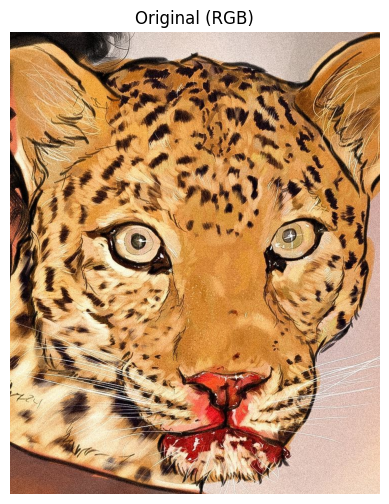

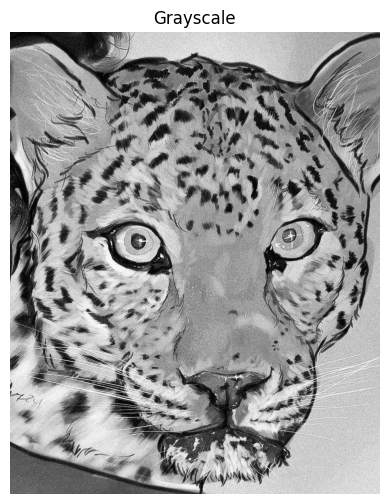

In [2]:
#UpLoad ONE image
from google.colab import files
up = files.upload()
IMG = list(up.keys())[0]
# Basics
import cv2, numpy as np, matplotlib.pyplot as plt
# Read & prep
bgr = cv2.imread(IMG, cv2.IMREAD_COLOR)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
def show(im, title="", size=5, cmap=None):
    plt.figure(figsize=(size,size))
    if im.ndim == 2:
        plt.imshow(im, cmap=cmap or "gray")
    else:
        plt.imshow(im)
    plt.title(title)
    plt.axis("off")
    plt.show()
show(rgb, "Original (RGB)", 6)
show(gray, "Grayscale", 6, "gray")

**Task 1 -- 2D FFT +shift (center the low frequencies)**

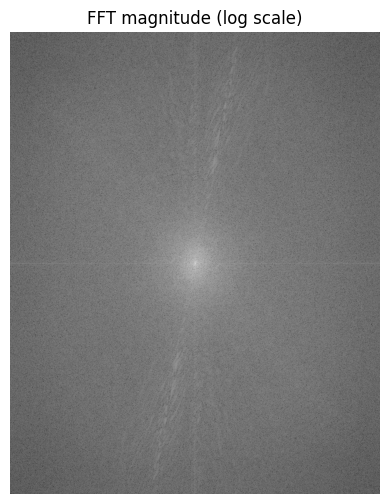

In [6]:
F = np.fft.fft2(gray)
Fc = np.fft.fftshift(F)
mag_log = np.log1p(np.abs(Fc))
show(mag_log, "FFT magnitude (log scale)", 6, "gray")

**Task 2 -- Magnitude and Phase (view separately)**





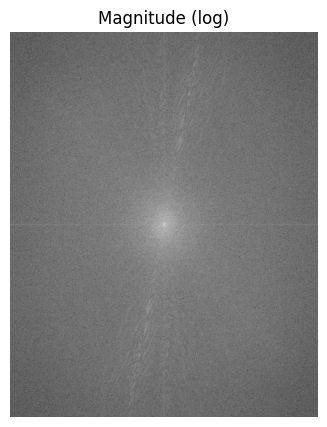

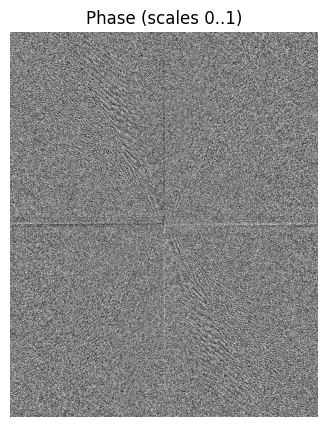

In [9]:
mag = np.abs(Fc) # strength of frequencies
ph = np.angle(Fc) # angle = phase

show(np.log1p(mag),"Magnitude (log)",5,"gray")
show((ph+ np.pi)/(2*np.pi),"Phase (scales 0..1)",5,"gray")

**Task 3 -- Inverse FFT (prove round-trip works)**

Max absolute difference: 1


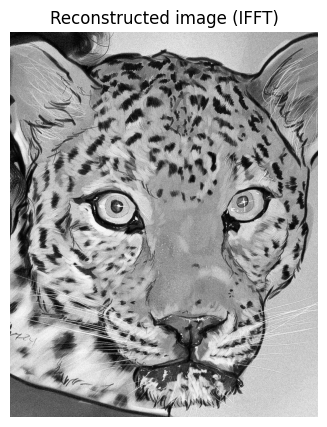

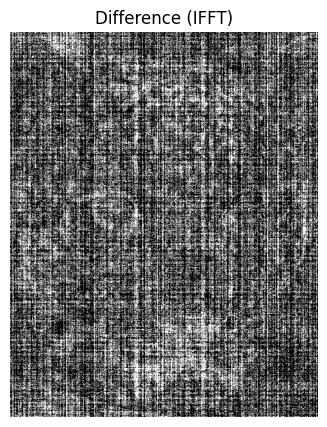

In [11]:
F_un =np.fft.ifftshift(Fc) #undo the shift
rec = np.fft.ifft2(F_un).real
rec8 = np.clip(rec, 0, 255).astype(np.uint8)

diff = cv2.absdiff(gray, rec8)
print("Max absolute difference:", diff.max())
show(rec8, "Reconstructed image (IFFT)",5,"gray")
show(diff, "Difference (IFFT)",5,"gray")

**Task 4 -- Ideal Low-Pass (keep only center circle)**

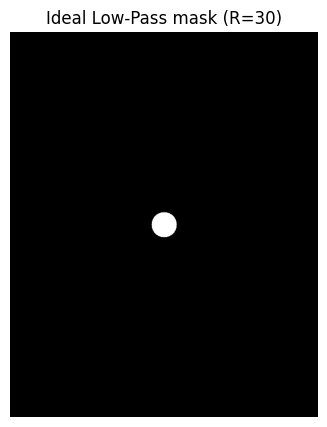

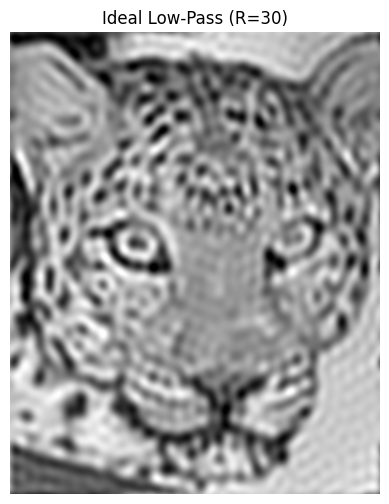

In [12]:
H, W = gray.shape
Y, X =np.ogrid[:H, :W]
cy, cx = H//2, W//2
R = 30 #radius in pixels (try 10 / 30 / 60)

LP = ((X-cx)**2 + (Y-cy)**2 <= R*R).astype(np.float32) #1 inside the circle, else 0
show(LP, f"Ideal Low-Pass mask (R={R})",5,"gray")

Fc_lp = Fc * LP
img_lp =np.fft.ifft2(np.fft.ifftshift(Fc_lp)).real
show(np.clip(img_lp, 0, 255).astype(np.uint8), f"Ideal Low-Pass (R={R})",6,"gray")

Task 5 -- Ideal High-Pass (remove center)

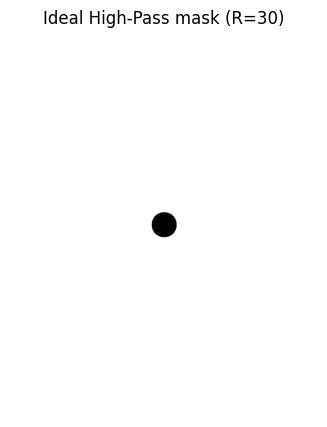

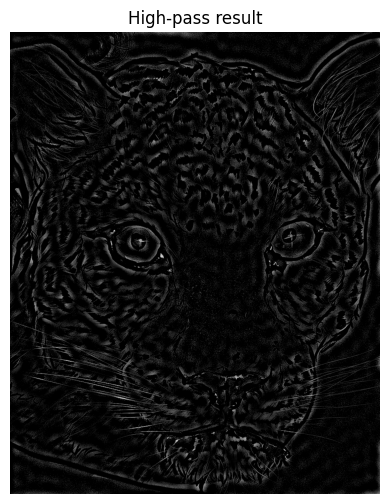

In [13]:
HP = 1.0 -LP
show (HP , f"Ideal High-Pass mask (R={R})",5,"gray")
fC_hp = Fc * HP
img_hp = np.fft.ifft2(np.fft.ifftshift(fC_hp)).real
show(np.clip(img_hp,0,255).astype(np.uint8),"High-pass result", 6 , "gray")

**Task 6: Gaussian Low-Pass (gentle, no ringing)**

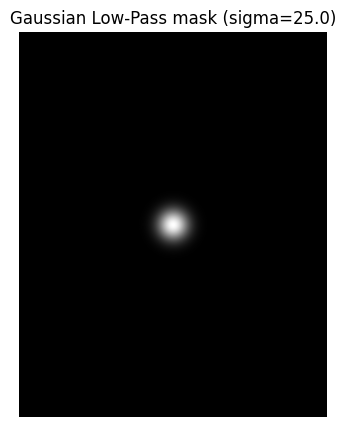

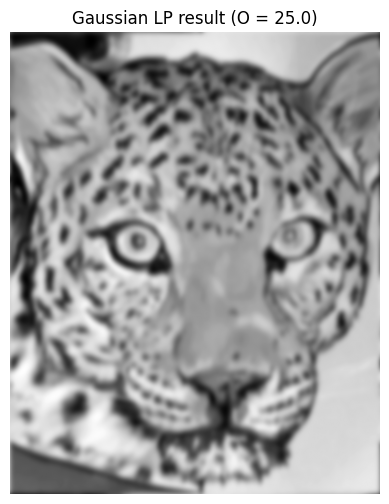

In [14]:
sigma = 25.0
G = np.exp(-((X-cx)**2 + (Y-cy)**2)/(2*sigma*sigma))
show(G, f"Gaussian Low-Pass mask (sigma={sigma})",5,"gray")
Fc_lp = Fc * G
img_lp = np.fft.ifft2(np.fft.ifftshift(Fc_lp)).real
show(np.clip(img_lp, 0, 255).astype(np.uint8),f"Gaussian LP result (O = {sigma})",6,"gray")

**Task 6: Gaussian Low-Pass (gentle - no ringing)**

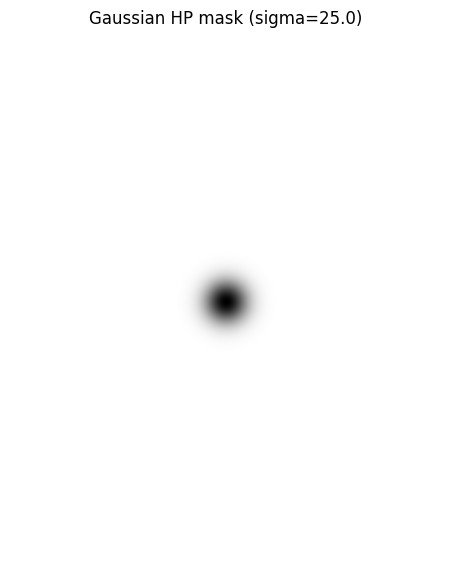

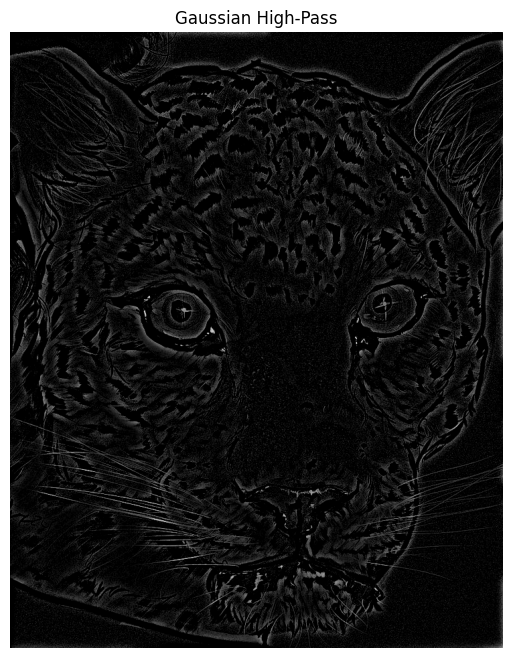

In [16]:
sigma = 25.0
G = np.exp(-((X - cx)**2 + (Y - cy)**2) / (2 * sigma**2))
H = 1 - G

show(H, f"Gaussian HP mask (sigma={sigma})", 7, "gray")

Fc_hp = Fc * H

img_hp = np.fft.ifft2(np.fft.ifftshift(Fc_hp)).real

show(np.clip(img_hp, 0, 255).astype(np.uint8),
     "Gaussian High-Pass", 8, "gray")

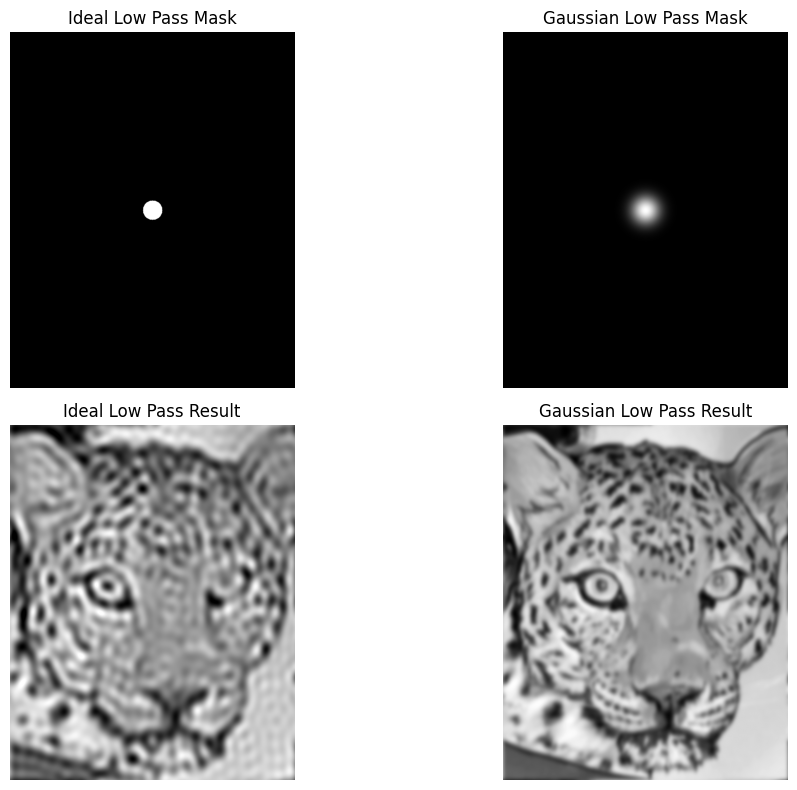

In [19]:
import numpy as np
import matplotlib.pyplot as plt

D0 = 25.0
sigma = 25.0

# Distance from center
D = np.sqrt((X - cx)**2 + (Y - cy)**2)

# Ideal Low Pass Filter
ILPF = np.zeros_like(D)
ILPF[D <= D0] = 1

# Gaussian Low Pass Filter
GLPF = np.exp(-(D**2) / (2 * sigma**2))

# Apply Ideal LPF
Fc_ILPF = Fc * ILPF
img_ILPF = np.fft.ifft2(
    np.fft.ifftshift(Fc_ILPF)
).real

# Apply Gaussian LPF
Fc_GLPF = Fc * GLPF
img_GLPF = np.fft.ifft2(
    np.fft.ifftshift(Fc_GLPF)
).real

# Side-by-side comparison
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(ILPF, cmap='gray')
plt.title("Ideal Low Pass Mask")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(GLPF, cmap='gray')
plt.title("Gaussian Low Pass Mask")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(np.clip(img_ILPF, 0, 255).astype(np.uint8),
           cmap='gray')
plt.title("Ideal Low Pass Result")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(np.clip(img_GLPF, 0, 255).astype(np.uint8),
           cmap='gray')
plt.title("Gaussian Low Pass Result")
plt.axis('off')

plt.tight_layout()
plt.show()

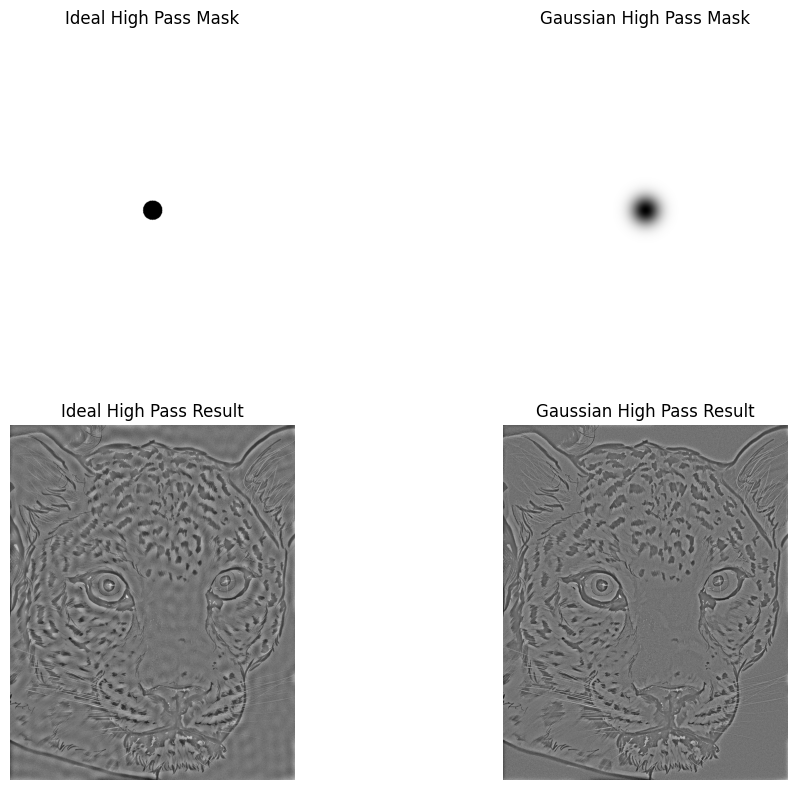

In [20]:
import numpy as np
import matplotlib.pyplot as plt

D0 = 25.0
sigma = 25.0

# Distance from center
D = np.sqrt((X - cx)**2 + (Y - cy)**2)

# Ideal High Pass Filter
IHPF = np.ones_like(D)
IHPF[D <= D0] = 0

# Gaussian High Pass Filter
GHPF = 1 - np.exp(-(D**2) / (2 * sigma**2))

# Apply Ideal HPF
Fc_IHPF = Fc * IHPF
img_IHPF = np.fft.ifft2(
    np.fft.ifftshift(Fc_IHPF)
).real

# Apply Gaussian HPF
Fc_GHPF = Fc * GHPF
img_GHPF = np.fft.ifft2(
    np.fft.ifftshift(Fc_GHPF)
).real

# Side-by-side comparison
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(IHPF, cmap='gray')
plt.title("Ideal High Pass Mask")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(GHPF, cmap='gray')
plt.title("Gaussian High Pass Mask")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(img_IHPF, cmap='gray')
plt.title("Ideal High Pass Result")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_GHPF, cmap='gray')
plt.title("Gaussian High Pass Result")
plt.axis('off')

plt.tight_layout()
plt.show()